# SAM2.1 Baseline Segmentation Metrics — Denoised Input
Compares vanilla SAM2.1 Hiera-B+ (no fine-tuning) predicted nerve masks against hand-drawn ground truth.

**Metrics:** IoU, Dice, Hausdorff Distance, mAP / mAP@50  
**GT source:** AlmeidaDenoised2_nerve, BorgesDenoised2_nerve, BritoDenoised2_nerve  
**Predictions:** `D:/sam2-results/denoised/<patient>/masks/`  
**Source images:** Speckle2Self denoised — `speckle2self-results/git_inf/260720-cropped4/epoch199/<patient>/`

In [294]:
import os
import re
import numpy as np
import pandas as pd
from PIL import Image
from scipy.spatial.distance import directed_hausdorff

In [295]:
GT_ROOT   = r"D:\annotated_pn"
PRED_ROOT = r"D:\sam2-results\denoised"

PATIENTS = {
    "Almeida": "AlmeidaDenoised2_nerve",
    "Borges":  "BorgesDenoised2_nerve",
    "Brito":   "BritoDenoised2_nerve",
}

LABEL_MAP = {"Almeida": "Patient 1", "Borges": "Patient 2", "Brito": "Patient 3"}

In [296]:
def compute_iou(pred, gt):
    p, g = pred.astype(bool), gt.astype(bool)
    inter = np.logical_and(p, g).sum()
    union = np.logical_or(p, g).sum()
    return float(inter / union) if union > 0 else 1.0

def compute_dice(pred, gt):
    p, g = pred.astype(bool), gt.astype(bool)
    inter = np.logical_and(p, g).sum()
    denom = p.sum() + g.sum()
    return float(2 * inter / denom) if denom > 0 else 1.0

def compute_hausdorff(pred, gt):
    pred_pts = np.column_stack(np.where(pred.astype(bool)))
    gt_pts   = np.column_stack(np.where(gt.astype(bool)))
    if len(pred_pts) == 0 or len(gt_pts) == 0:
        return float("nan")
    return max(directed_hausdorff(pred_pts, gt_pts)[0],
               directed_hausdorff(gt_pts, pred_pts)[0])

MAP_THRESHOLDS = np.arange(0.50, 1.00, 0.05)

def compute_map(iou_scores):
    ap_per_thresh = [(iou_scores >= t).mean() for t in MAP_THRESHOLDS]
    return float(np.mean(ap_per_thresh)), float(ap_per_thresh[0])

def load_binary(path):
    return (np.array(Image.open(path).convert('L')) > 0)

def metrics_for_pair(pred_path, gt_path):
    pred = load_binary(pred_path)
    gt   = load_binary(gt_path)
    return dict(iou=compute_iou(pred, gt),
                dice=compute_dice(pred, gt),
                hausdorff=compute_hausdorff(pred, gt))

In [297]:
# GT:   Label_N_{base}_denoised.png  → key: {base}
# Pred: {base}_denoised_mask.png     → key: {base}

def frame_key_from_gt(fname):
    s = re.sub(r'^Label_\d+_', '', fname)
    return s.replace('_denoised.png', '').replace('.png', '')

def frame_key_from_pred(fname):
    return fname.replace('_denoised_mask.png', '').replace('_mask.png', '')


records = []

for patient, gt_folder in PATIENTS.items():
    gt_dir   = os.path.join(GT_ROOT, gt_folder)
    pred_dir = os.path.join(PRED_ROOT, patient, "masks")

    if not os.path.exists(pred_dir):
        print(f"[SKIP] {patient}: predictions not found at {pred_dir}")
        continue

    gt_index   = {frame_key_from_gt(f): os.path.join(gt_dir, f)
                  for f in os.listdir(gt_dir) if f.endswith('.png')}
    pred_index = {frame_key_from_pred(f): os.path.join(pred_dir, f)
                  for f in os.listdir(pred_dir) if f.endswith('.png')}

    for gt_key, gt_path in gt_index.items():
        pred_path = pred_index.get(gt_key)
        if pred_path is None:
            print(f"  [WARN] No prediction for GT key: {gt_key} ({patient})")
            continue
        records.append({"patient": patient, "frame_key": gt_key,
                         "gt_path": gt_path, "pred_path": pred_path})

df = pd.DataFrame(records)
print(f"Total matched: {len(df)}")
print(df.groupby('patient').size().rename('frames'))

Total matched: 134
patient
Almeida    42
Borges     49
Brito      43
Name: frames, dtype: int64


In [298]:
m = df.apply(lambda r: metrics_for_pair(r['pred_path'], r['gt_path']), axis=1)
df['iou']       = m.apply(lambda x: x['iou'])
df['dice']      = m.apply(lambda x: x['dice'])
df['hausdorff'] = m.apply(lambda x: x['hausdorff'])
print("Metrics computed.")
print(df[['patient', 'iou', 'dice', 'hausdorff']].head(5))

Metrics computed.
   patient       iou      dice  hausdorff
0  Almeida  0.452571  0.623131  46.000000
1  Almeida  0.405725  0.577247  58.463664
2  Almeida  0.402296  0.573768  51.264022
3  Almeida  0.640483  0.780847  11.180340
4  Almeida  0.392111  0.563333  52.430907


In [299]:
def summarise(group_df):
    iou  = group_df['iou'].dropna()
    dice = group_df['dice'].dropna()
    hd   = group_df['hausdorff'].dropna()
    map_, map50 = compute_map(iou.values)
    return pd.Series({
        'n':       len(iou),
        'IoU':     f"{iou.mean():.3f} ± {iou.std():.3f}",
        'Dice':    f"{dice.mean():.3f} ± {dice.std():.3f}",
        'HD (px)': f"{hd.mean():.1f} ± {hd.std():.1f}",
        'mAP':     f"{map_:.3f}",
        'mAP@50':  f"{map50:.3f}",
    })

rows = {LABEL_MAP[p]: summarise(gdf) for p, gdf in df.groupby('patient')}
rows['OVERALL'] = summarise(df)
summary = pd.DataFrame(rows).T
print("SAM2.1 baseline (denoised) — predictions vs GT")
print(summary.to_string())

SAM2.1 baseline (denoised) — predictions vs GT
             n            IoU           Dice      HD (px)    mAP mAP@50
Patient 1   42  0.467 ± 0.111  0.630 ± 0.098  38.6 ± 12.5  0.079  0.310
Patient 2   49  0.719 ± 0.077  0.834 ± 0.054   16.9 ± 9.8  0.492  1.000
Patient 3   43  0.702 ± 0.109  0.820 ± 0.082  19.2 ± 17.5  0.458  0.907
OVERALL    134  0.635 ± 0.150  0.765 ± 0.121  24.4 ± 16.5  0.351  0.754


In [300]:
def summarise_raw(group_df):
    iou  = group_df['iou'].dropna()
    dice = group_df['dice'].dropna()
    hd   = group_df['hausdorff'].dropna()
    map_, map50 = compute_map(iou.values)
    return pd.Series({
        'n':          len(iou),
        'IoU_mean':   round(iou.mean(),  4),
        'IoU_std':    round(iou.std(),   4),
        'Dice_mean':  round(dice.mean(), 4),
        'Dice_std':   round(dice.std(),  4),
        'HD_mean_px': round(hd.mean(),   2),
        'HD_std_px':  round(hd.std(),    2),
        'mAP':        round(map_,        4),
        'mAP@50':     round(map50,       4),
    })

rows_raw = {LABEL_MAP[p]: summarise_raw(gdf) for p, gdf in df.groupby('patient')}
rows_raw['OVERALL'] = summarise_raw(df)
summary_raw = pd.DataFrame(rows_raw).T
print(summary_raw.to_string())

summary_raw.to_csv(r"D:\sam2-results\sam2_metrics_dn.csv")
print("\nSaved → D:\\sam2-results\\sam2_metrics_dn.csv")

               n  IoU_mean  IoU_std  Dice_mean  Dice_std  HD_mean_px  HD_std_px     mAP  mAP@50
Patient 1   42.0    0.4671   0.1106     0.6296    0.0977       38.61      12.49  0.0786  0.3095
Patient 2   49.0    0.7190   0.0772     0.8341    0.0545       16.94       9.78  0.4918  1.0000
Patient 3   43.0    0.7022   0.1092     0.8199    0.0819       19.15      17.55  0.4581  0.9070
OVERALL    134.0    0.6346   0.1505     0.7655    0.1210       24.44      16.52  0.3515  0.7537

Saved → D:\sam2-results\sam2_metrics_dn.csv


In [ ]:
# ── XLSX export — sheet "Denoised" in sam2_metrics.xlsx ──────────────────────
from openpyxl.utils import get_column_letter

xlsx_path = os.path.join(OUT_DIR, 'sam2_metrics.xlsx')
ew_kwargs = dict(engine='openpyxl', mode='a', if_sheet_exists='replace') \
    if os.path.exists(xlsx_path) else dict(engine='openpyxl')
with pd.ExcelWriter(xlsx_path, **ew_kwargs) as writer:
    summary.to_excel(writer, sheet_name='Denoised', startrow=0)
    summary_raw.to_excel(writer, sheet_name='Denoised', startrow=len(summary) + 2)
    ws = writer.sheets['Denoised']
    for col_idx in range(1, ws.max_column + 1):
        col_letter = get_column_letter(col_idx)
        ws.column_dimensions[col_letter].width = max(
            (len(str(c.value)) for c in ws[col_letter] if c.value), default=8
        ) + 3
print(f'Saved → {xlsx_path}')

In [301]:
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display as ipy_display, Image as IPyImage

SOURCE_ROOT = r"D:\dissertation-results\speckle2self-results\git_inf\260720-cropped4\epoch199"
OUT_DIR     = os.getcwd()

def source_path(patient, frame_key):
    return os.path.join(SOURCE_ROOT, patient.lower(), f"{frame_key}_denoised.png")

def make_overlay(img_arr, mask_arr, color=(0, 200, 60), alpha=0.5):
    out = img_arr.copy().astype(np.float32)
    out[mask_arr.astype(bool)] = (
        out[mask_arr.astype(bool)] * (1 - alpha)
        + np.array(color, dtype=np.float32) * alpha
    )
    return out.astype(np.uint8)

def show_patient_samples(patient, n=3, seed=42):
    label = LABEL_MAP[patient]
    rows = df[df['patient'] == patient]
    if len(rows) == 0:
        print(f"{label}: no matched frames available")
        return
    samples = rows.sample(min(n, len(rows)), random_state=seed)

    fig, axes = plt.subplots(len(samples), 2, figsize=(11, 3.6 * len(samples)))
    if len(samples) == 1:
        axes = axes[np.newaxis, :]
    fig.suptitle(f"{label}", fontsize=13)

    for i, (_, r) in enumerate(samples.iterrows()):
        src       = np.array(Image.open(source_path(patient, r['frame_key'])).convert('RGB'))
        gt_mask   = load_binary(r['gt_path'])
        pred_mask = load_binary(r['pred_path'])

        axes[i, 0].imshow(make_overlay(src, gt_mask))
        axes[i, 0].set_title("Ground Truth", fontsize=8)
        axes[i, 0].axis('off')
        axes[i, 1].imshow(make_overlay(src, pred_mask))
        axes[i, 1].set_title(f"SAM2  IoU={r['iou']:.3f}  Dice={r['dice']:.3f}", fontsize=8)
        axes[i, 1].axis('off')

    plt.tight_layout()
    out_path = os.path.join(OUT_DIR, f"{label.replace(' ', '_')}_sam2_dn_samples.png")
    fig.savefig(out_path, dpi=150, bbox_inches='tight')
    plt.close(fig)
    ipy_display(IPyImage(filename=out_path))
    print(f"Saved → {out_path}")

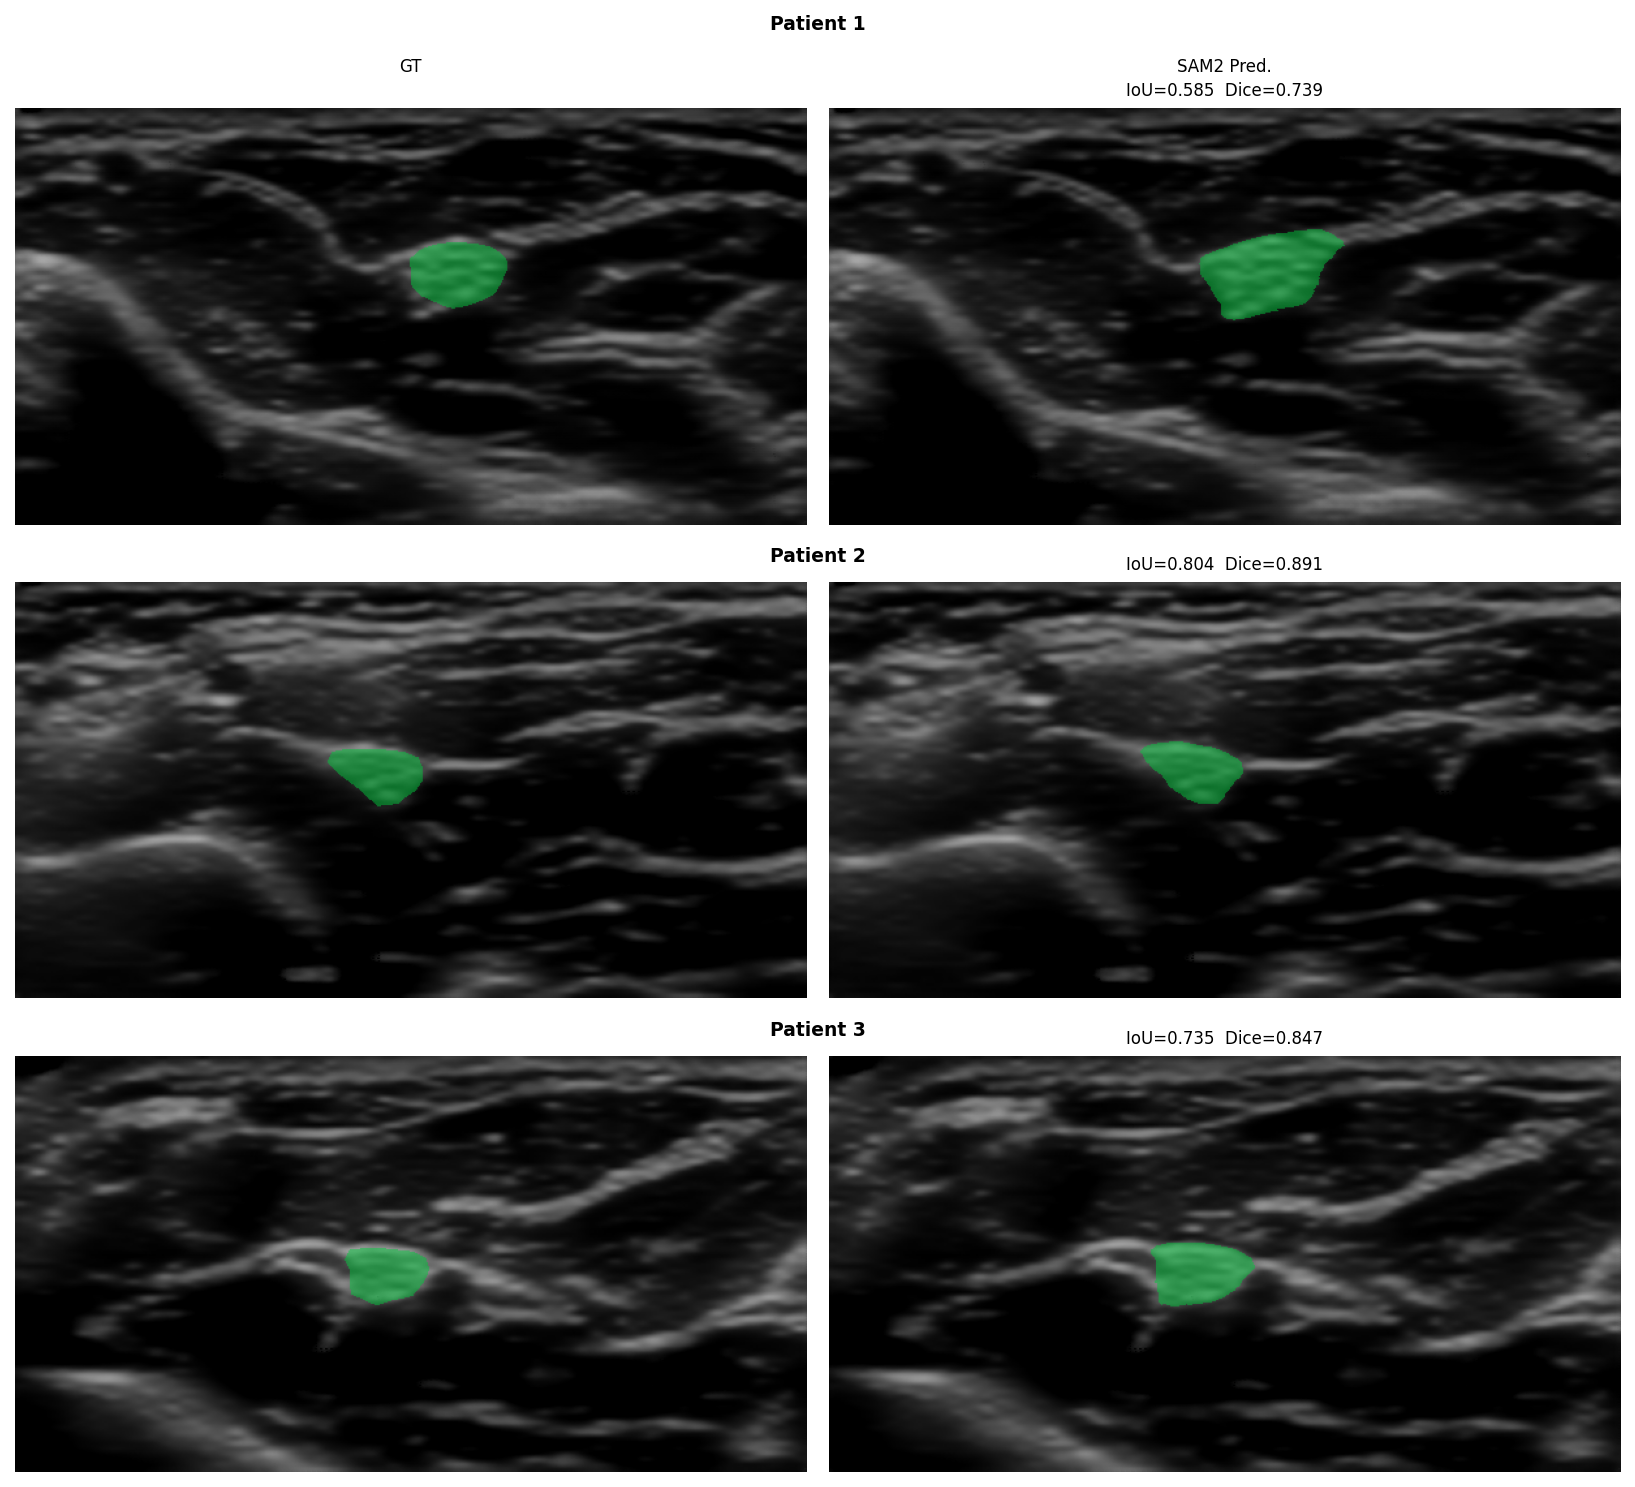

Saved → d:\graphs-n-tables\sam2\sam2_denoised_input_qualitative.png


In [302]:
# ── Mosaic: one random frame per patient ─────────────────────────────────────
def make_mosaic(seed=42):
    fig, axes = plt.subplots(len(PATIENTS), 2, figsize=(11, 3.7 * len(PATIENTS)))

    for row, patient in enumerate(PATIENTS):
        patient_rows = df[df['patient'] == patient]
        r = patient_rows.sample(1, random_state=seed).iloc[0]

        src       = np.array(Image.open(source_path(patient, r['frame_key'])).convert('RGB'))
        gt_mask   = load_binary(r['gt_path'])
        pred_mask = load_binary(r['pred_path'])

        axes[row, 0].imshow(make_overlay(src, gt_mask))
        axes[row, 0].axis('off')
        axes[row, 1].imshow(make_overlay(src, pred_mask))
        axes[row, 1].set_title(f"IoU={r['iou']:.3f}  Dice={r['dice']:.3f}", fontsize=8)
        axes[row, 1].axis('off')

    plt.tight_layout()
    plt.subplots_adjust(top=0.88)

    x_gt   = (axes[0, 0].get_position().x0 + axes[0, 0].get_position().x1) / 2
    x_pred = (axes[0, 1].get_position().x0 + axes[0, 1].get_position().x1) / 2
    x_mid  = (axes[0, 0].get_position().x0 + axes[0, 1].get_position().x1) / 2

    y_top_row0 = axes[0, 0].get_position().y1
    fig.text(x_gt,   y_top_row0 + 0.020, 'GT',         ha='center', va='bottom', fontsize=8)
    fig.text(x_pred, y_top_row0 + 0.020, 'SAM2 Pred.', ha='center', va='bottom', fontsize=8)

    for row, patient in enumerate(PATIENTS):
        label   = LABEL_MAP[patient]
        y_top   = axes[row, 0].get_position().y1
        y_label = y_top + 0.045 if row == 0 else y_top + 0.010
        fig.text(x_mid, y_label, label, ha='center', va='bottom',
                 fontsize=9, fontweight='bold')

    out_path = os.path.join(OUT_DIR, "sam2_denoised_input_qualitative.png")
    fig.savefig(out_path, dpi=150, bbox_inches='tight')
    plt.close(fig)
    ipy_display(IPyImage(filename=out_path))
    print(f"Saved → {out_path}")

make_mosaic()

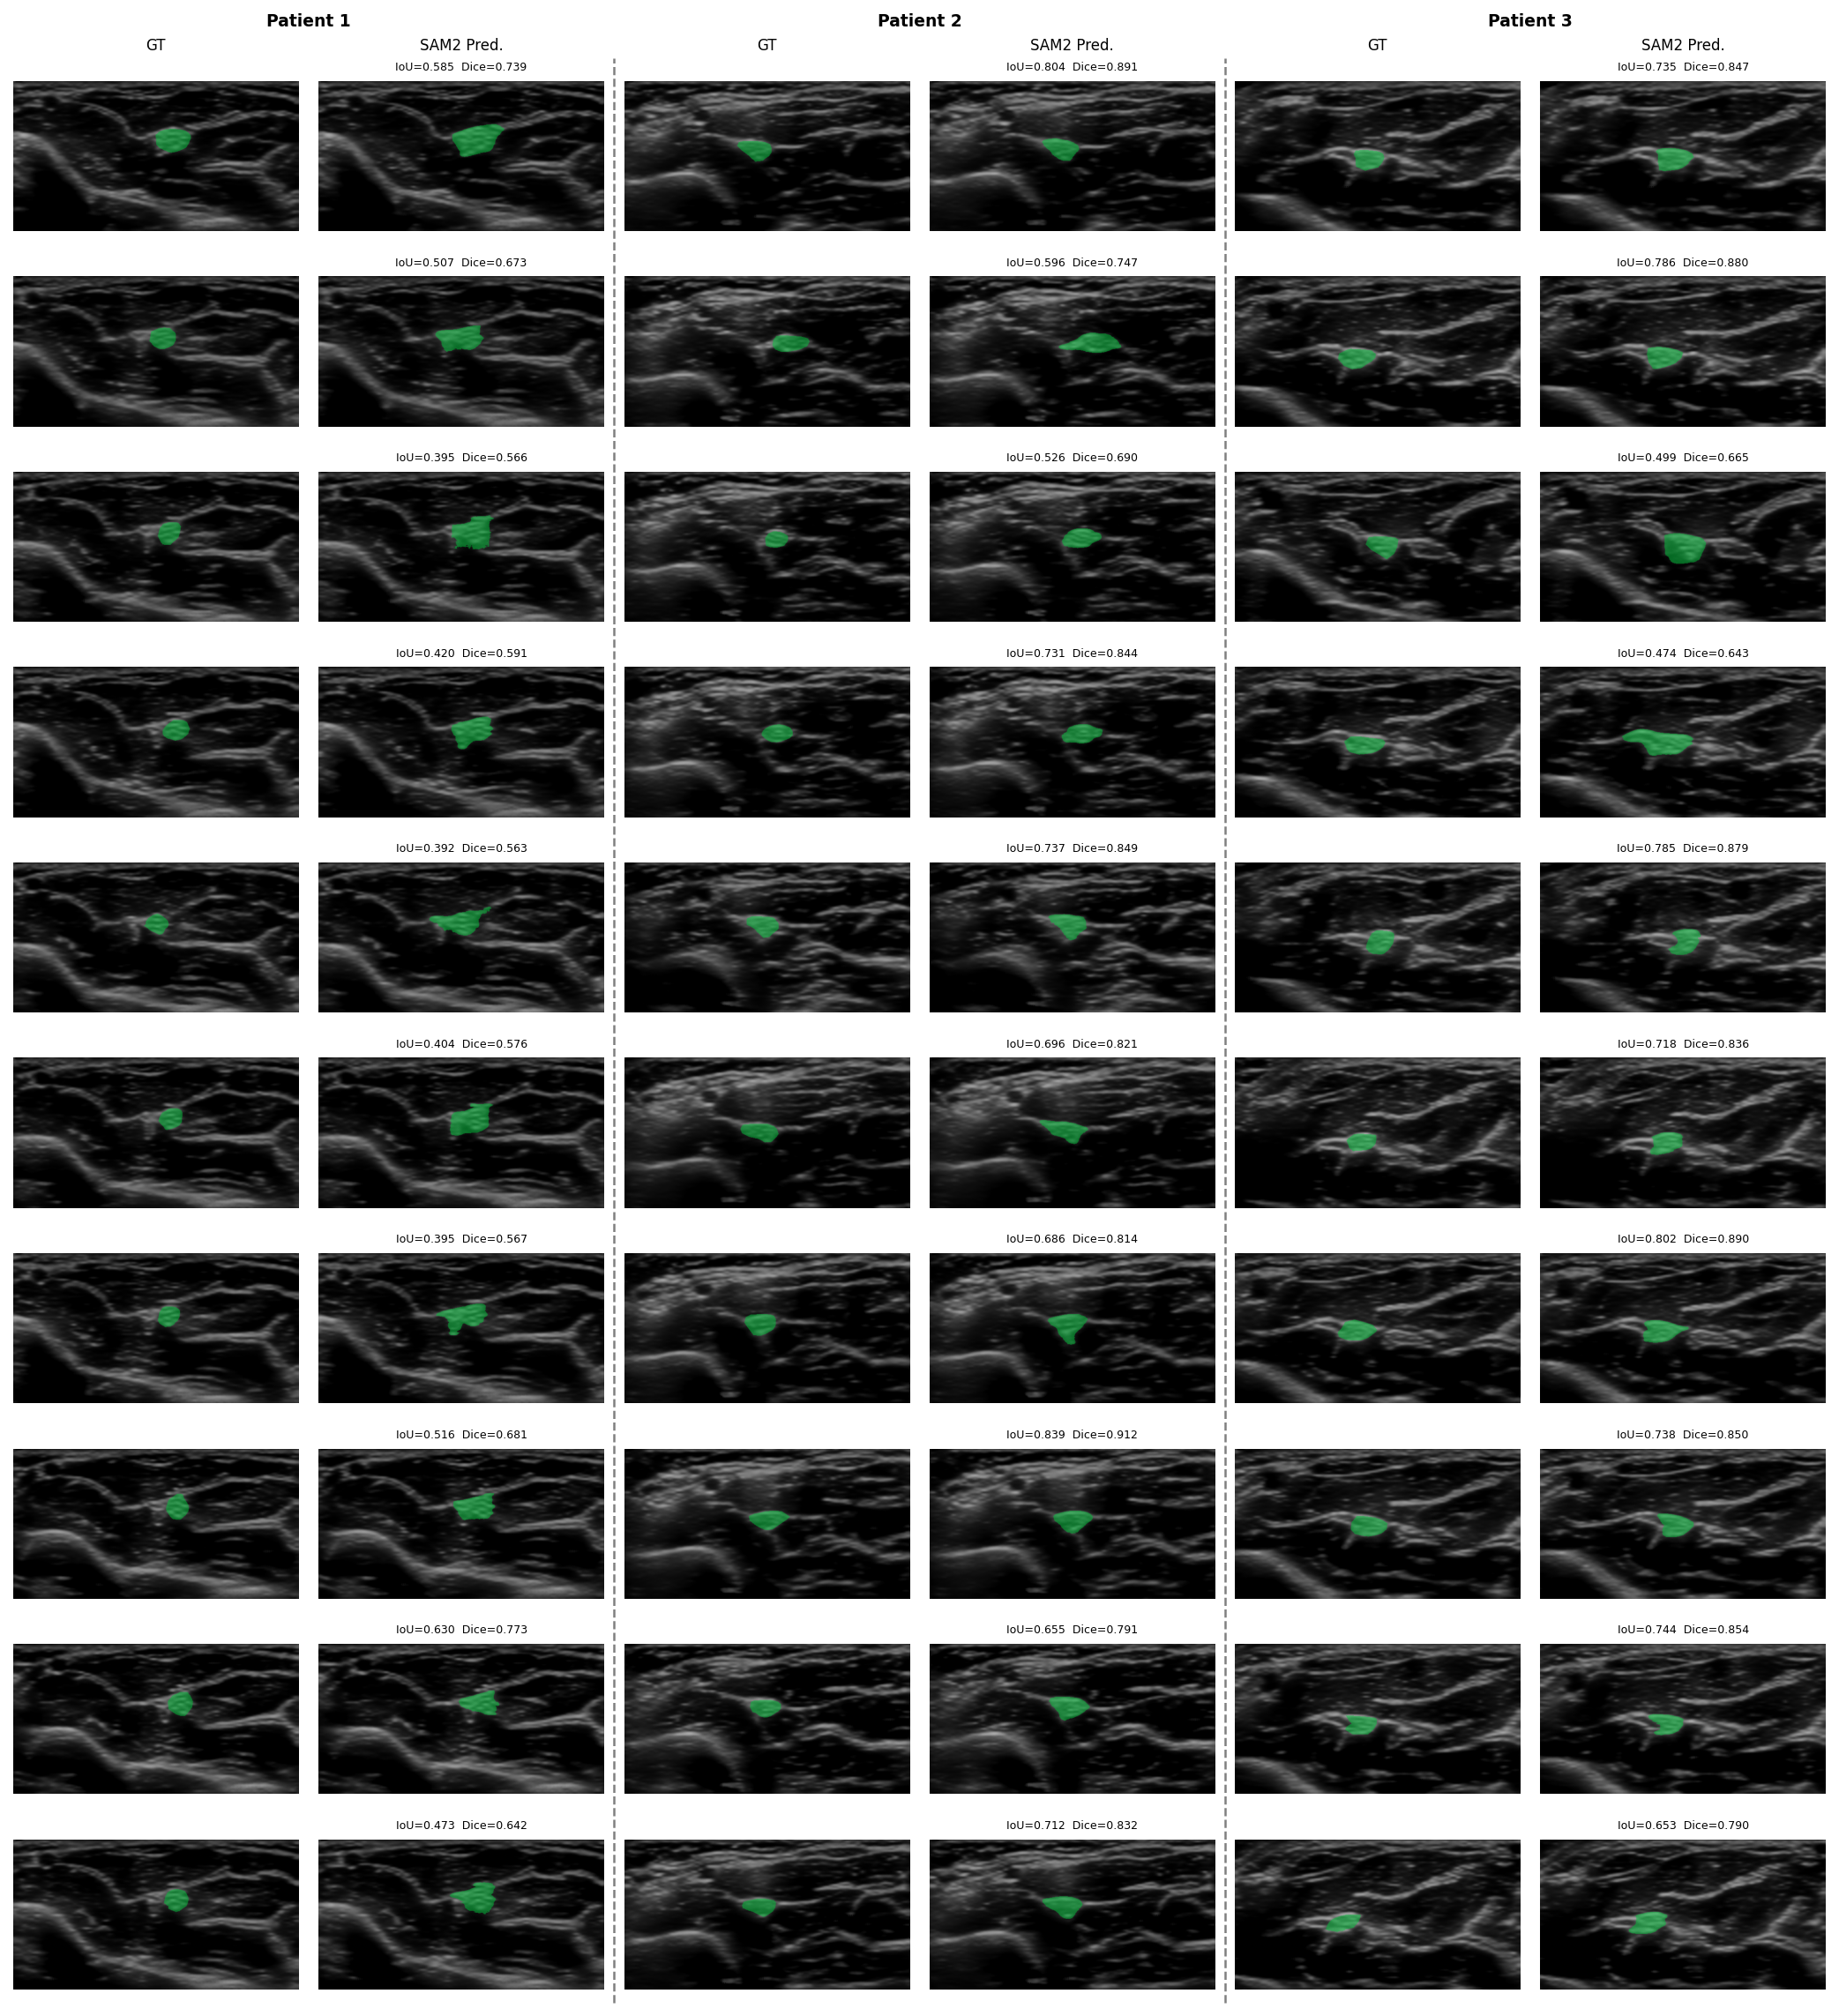

Saved → d:\graphs-n-tables\sam2\sam2_denoised_all_patients_grid.png


In [303]:
# ── All-patients grid: 10 frames × 3 patients (each patient = GT + prediction column) ──
from matplotlib.lines import Line2D

N_FRAMES = 10
SEED     = 42

fig, axes = plt.subplots(N_FRAMES, len(PATIENTS) * 2, figsize=(14, 1.5 * N_FRAMES))

for col_pair, patient in enumerate(PATIENTS):
    patient_rows = df[df['patient'] == patient]
    samples      = patient_rows.sample(min(N_FRAMES, len(patient_rows)), random_state=SEED)

    col_gt   = col_pair * 2
    col_pred = col_pair * 2 + 1

    for row, (_, r) in enumerate(samples.iterrows()):
        src       = np.array(Image.open(source_path(patient, r['frame_key'])).convert('RGB'))
        gt_mask   = load_binary(r['gt_path'])
        pred_mask = load_binary(r['pred_path'])

        axes[row, col_gt].imshow(make_overlay(src, gt_mask))
        axes[row, col_gt].axis('off')
        axes[row, col_pred].imshow(make_overlay(src, pred_mask))
        axes[row, col_pred].set_title(f"IoU={r['iou']:.3f}  Dice={r['dice']:.3f}", fontsize=6)
        axes[row, col_pred].axis('off')

plt.tight_layout()

y_top     = axes[0, 0].get_position().y1
y_headers = y_top + 0.014
y_patient = y_top + 0.026

for col_pair, patient in enumerate(PATIENTS):
    label    = LABEL_MAP[patient]
    col_gt   = col_pair * 2
    col_pred = col_pair * 2 + 1

    x_gt   = (axes[0, col_gt].get_position().x0   + axes[0, col_gt].get_position().x1)   / 2
    x_pred = (axes[0, col_pred].get_position().x0  + axes[0, col_pred].get_position().x1) / 2
    x_mid  = (axes[0, col_gt].get_position().x0   + axes[0, col_pred].get_position().x1)  / 2

    fig.text(x_mid,  y_patient,  label,         ha='center', va='bottom', fontsize=9, fontweight='bold')
    fig.text(x_gt,   y_headers,  'GT',          ha='center', va='bottom', fontsize=8)
    fig.text(x_pred, y_headers,  'SAM2 Pred.',  ha='center', va='bottom', fontsize=8)

for sep_col in [1, 3]:
    x_left  = axes[0, sep_col].get_position().x1
    x_right = axes[0, sep_col + 1].get_position().x0
    x_mid   = (x_left + x_right) / 2
    fig.add_artist(Line2D([x_mid, x_mid], [0.01, 0.99],
                          transform=fig.transFigure,
                          color='gray', linewidth=1.2, linestyle='--'))

out_path = os.path.join(OUT_DIR, "sam2_denoised_all_patients_grid.png")
fig.savefig(out_path, dpi=150, bbox_inches='tight')
plt.close(fig)
ipy_display(IPyImage(filename=out_path))
print(f"Saved → {out_path}")